# Bài 1 - Phân tích hành khách Titanic
**Nguồn dữ liệu:** [Titanic — Machine Learning from Disaster (Kaggle)](https://www.kaggle.com/competitions/titanic/data)
Nếu chưa có `train.csv`, tải file này trong mục **Data** của cuộc thi Kaggle ở đường dẫn phía trên.

## 1.0. Chuẩn bị thư viện

-Pandas: Đọc và xử lý bảng dữ liệu.

-Numpy: Tính thống kê.

-Matplotlib: Vẽ biểu đồ.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

print("Đã tải thư viện thành công!")

Đã tải thư viện thành công!


## 1.1. Đọc file CSV

In [2]:
try:
    from google.colab import files
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("Bạn chưa chọn file CSV.")
    ten_file = next(iter(uploaded))
except ImportError:
    ten_file = "train.csv"
df = pd.read_csv(ten_file)
print("Đọc dữ liệu thành công!")
print("Tên file:", ten_file)

Saving train.csv to train.csv
Đọc dữ liệu thành công!
Tên file: train.csv


In [3]:
# Xem 5 dòng đầu tiên
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1.2. Xem kích thước, kiểu dữ liệu và thống kê mô tả

### 1.2.1. Kích thước dữ liệu

In [4]:
so_dong, so_cot = df.shape

print("Số dòng:", so_dong)
print("Số cột:", so_cot)

Số dòng: 891
Số cột: 12


### 1.2.2. Kiểu dữ liệu và thông tin tổng quát

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
# Kiểu dữ liệu riêng của từng cột
df.dtypes

,0
PassengerId,int64
Survived,int64
Pclass,int64
Name,object
Sex,object
Age,float64
SibSp,int64
Parch,int64
Ticket,object
Fare,float64


### 1.2.3. Thống kê mô tả

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Dooley, Mr. Patrick",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 1.3. Kiểm tra và xử lý giá trị thiếu

Trước tiên đếm số lượng và tỷ lệ phần trăm giá trị thiếu của từng cột.

In [8]:
bang_thieu = pd.DataFrame({
    "So_gia_tri_thieu": df.isna().sum(),
    "Ty_le_thieu_%": (df.isna().mean() * 100).round(2)
})

bang_thieu

,So_gia_tri_thieu,Ty_le_thieu_%
PassengerId,0,0.00
Survived,0,0.00
Pclass,0,0.00
Name,0,0.00
Sex,0,0.00
Age,177,19.87
SibSp,0,0.00
Parch,0,0.00
Ticket,0,0.00
Fare,0,0.00


Vậy cột age và cột cabin bị thiếu.

--> Xử lý: df_clean để giữ nguyên dữ liệu gốc trong df, xử lý trên bản sao:

- Age (tuổi): điền bằng trung vị-median (ít bị ảnh hướng bởi giá trị ngoại lai)
- Embarked (cảng lên tàu): điền bằng mode (giá trị xuất hiện nhiều nhất)
- Cabin (số cabin): điền chuỗi Unknown (Không tự dự đoán được)

In [9]:
df_clean = df.copy()
# Điền tuổi bị thiếu bằng trung vị
tuoi_trung_vi = df_clean["Age"].median()
df_clean["Age"] = df_clean["Age"].fillna(tuoi_trung_vi)
# Điền cảng lên tàu bị thiếu bằng giá trị xuất hiện nhiều nhất
cang_pho_bien = df_clean["Embarked"].mode()[0]
df_clean["Embarked"] = df_clean["Embarked"].fillna(cang_pho_bien)
# Cabin bị thiếu nhiều: đánh dấu là Unknown
df_clean["Cabin"] = df_clean["Cabin"].fillna("Unknown")
print("Đã xử lý giá trị thiếu.")
print("Trung vị Age dùng để điền:", tuoi_trung_vi)
print("Giá trị Embarked dùng để điền:", cang_pho_bien)

Đã xử lý giá trị thiếu.
Trung vị Age dùng để điền: 28.0
Giá trị Embarked dùng để điền: S


In [10]:
# Kiểm tra lại: các cột còn bao nhiêu giá trị thiếu?
df_clean.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


--> Dữ liệu đã hoàn tất xử lý

## 1.4. So sánh tỷ lệ sống sót theo giới tính và hạng vé

Trong dữ liệu:
- Survived = 1: sống sót
- Survived = 0: đăng xuất
- Sex: giới tính.
- Pclass: hạng vé (1, 2 hoặc 3).

Tỷ lệ sống sót: Trung bình của survived.

In [11]:
# Tỷ lệ sống sót theo giới tính
song_theo_gioi_tinh = (
    df_clean.groupby("Sex")["Survived"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "Ty_le_song", "count": "So_hanh_khach"})
)

song_theo_gioi_tinh["Ty_le_song_%"] = song_theo_gioi_tinh["Ty_le_song"] * 100
song_theo_gioi_tinh

,Ty_le_song,So_hanh_khach,Ty_le_song_%
Sex,,,
female,0.742038,314,74.203822
male,0.188908,577,18.890815


In [12]:
# Tỷ lệ sống sót theo hạng vé
song_theo_hang_ve = (
    df_clean.groupby("Pclass")["Survived"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "Ty_le_song", "count": "So_hanh_khach"})
)

song_theo_hang_ve["Ty_le_song_%"] = song_theo_hang_ve["Ty_le_song"] * 100
song_theo_hang_ve

,Ty_le_song,So_hanh_khach,Ty_le_song_%
Pclass,,,
1,0.629630,216,62.962963
2,0.472826,184,47.282609
3,0.242363,491,24.236253


So sánh:

In [13]:
nhom_gioi_tinh_cao_nhat = song_theo_gioi_tinh["Ty_le_song"].idxmax()
nhom_hang_ve_cao_nhat = song_theo_hang_ve["Ty_le_song"].idxmax()

print(
    "Giới tính có tỷ lệ sống sót cao nhất:",
    nhom_gioi_tinh_cao_nhat,
    f"({song_theo_gioi_tinh.loc[nhom_gioi_tinh_cao_nhat, 'Ty_le_song_%']:.2f}%)"
)

print(
    "Hạng vé có tỷ lệ sống sót cao nhất:",
    nhom_hang_ve_cao_nhat,
    f"({song_theo_hang_ve.loc[nhom_hang_ve_cao_nhat, 'Ty_le_song_%']:.2f}%)"
)

Giới tính có tỷ lệ sống sót cao nhất: female (74.20%)
Hạng vé có tỷ lệ sống sót cao nhất: 1 (62.96%)


## 1.5. Dùng NumPy tính trung bình, trung vị và độ lệch chuẩn

Ta tính các thống kê cho hai cột số Age và Fare trên dữ liệu đã làm sạch.
Đại lượng tính: Trung bình (mean), trung vị (median), độ lệch chuẩn (std).
Trong NumPy:
- ddof=0: độ lệch chuẩn tổng thể (mặc định).
- ddof=1: độ lệch chuẩn mẫu (Tức là lấy đại diện chứ không phải toàn thể)

In [14]:
for cot in ["Age", "Fare"]:
    gia_tri = df_clean[cot].dropna().to_numpy()

    print(f"--- Thống kê cột {cot} ---")
    print("Trung bình:", np.mean(gia_tri))
    print("Trung vị:", np.median(gia_tri))
    print("Độ lệch chuẩn tổng thể (ddof=0):", np.std(gia_tri, ddof=0))
    print("Độ lệch chuẩn mẫu (ddof=1):", np.std(gia_tri, ddof=1))
    print()

--- Thống kê cột Age ---
Trung bình: 29.36158249158249
Trung vị: 28.0
Độ lệch chuẩn tổng thể (ddof=0): 13.012388272793666
Độ lệch chuẩn mẫu (ddof=1): 13.019696550973201

--- Thống kê cột Fare ---
Trung bình: 32.204207968574636
Trung vị: 14.4542
Độ lệch chuẩn tổng thể (ddof=0): 49.6655344447741
Độ lệch chuẩn mẫu (ddof=1): 49.6934285971809



## 1.6. Trực quan hóa dữ liệu

### 1.6.1. Biểu đồ cột — tỷ lệ sống sót theo giới tính và hạng vé

Mỗi cột biểu diễn tỷ lệ hành khách sống sót trong một nhóm.

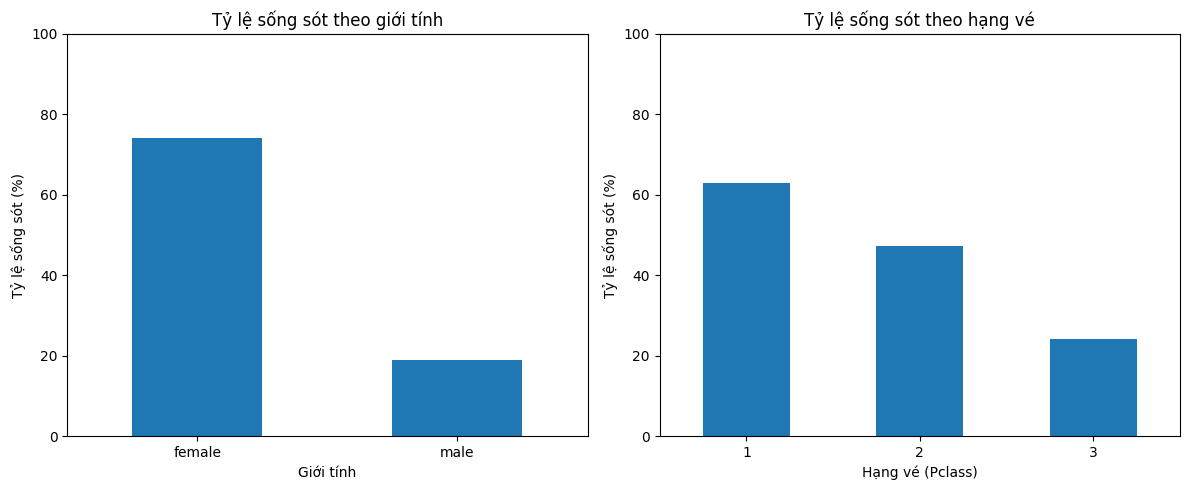

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Tỷ lệ sống sót theo giới tính
(song_theo_gioi_tinh["Ty_le_song"] * 100).plot(
    kind="bar", ax=axes[0], rot=0
)
axes[0].set_title("Tỷ lệ sống sót theo giới tính")
axes[0].set_xlabel("Giới tính")
axes[0].set_ylabel("Tỷ lệ sống sót (%)")
axes[0].set_ylim(0, 100)

# Tỷ lệ sống sót theo hạng vé
(song_theo_hang_ve["Ty_le_song"] * 100).plot(
    kind="bar", ax=axes[1], rot=0
)
axes[1].set_title("Tỷ lệ sống sót theo hạng vé")
axes[1].set_xlabel("Hạng vé (Pclass)")
axes[1].set_ylabel("Tỷ lệ sống sót (%)")
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

### 1.6.2. Histogram - phân bố độ tuổi

Histogram (biểu đồ tần số) cho thấy số lượng hành khách ở các khoảng tuổi khác nhau.

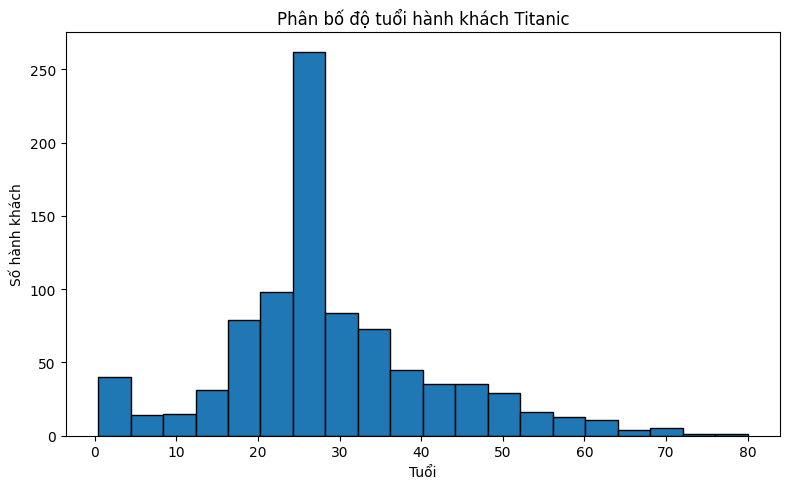

In [16]:
plt.figure(figsize=(8, 5))
plt.hist(df_clean["Age"], bins=20, edgecolor="black")
plt.title("Phân bố độ tuổi hành khách Titanic")
plt.xlabel("Tuổi")
plt.ylabel("Số hành khách")
plt.tight_layout()
plt.show()

### 1.6.3. Boxplot - phân bố giá vé theo hạng vé

<Figure size 800x500 with 0 Axes>

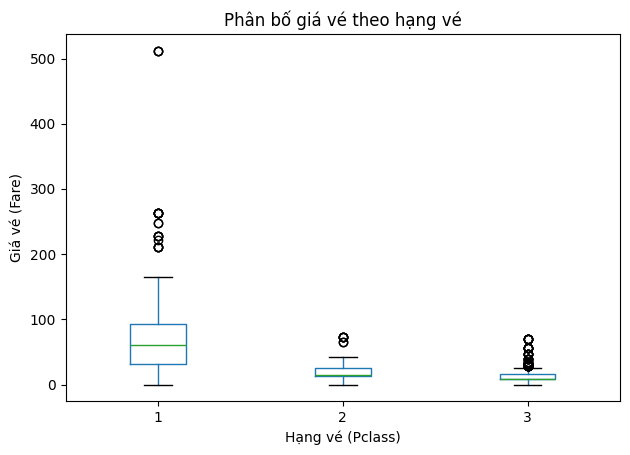

In [17]:
plt.figure(figsize=(8, 5))
df_clean.boxplot(column="Fare", by="Pclass", grid=False)
plt.title("Phân bố giá vé theo hạng vé")
plt.suptitle("")
plt.xlabel("Hạng vé (Pclass)")
plt.ylabel("Giá vé (Fare)")
plt.tight_layout()
plt.show()